# Survey logs to lightcurve fit

This page walks through the complete chain most users need: take a **real survey**, put **supernovae** in the sky,
get the **lightcurves** the survey would have collected, and **fit** them. Each step is timed (on a laptop CPU),
so you know what to expect when scaling up.

1. Load the ZTF survey from its real observing logs.
2. Draw one year of Type Ia supernovae (SNe Ia).
3. Build the dataset of simulated lightcurves.
4. Keep the well-sampled lightcurves (at least 5 detections) and fit them with SALT2,
   using either [sncosmo](https://sncosmo.readthedocs.io) (target by target) or
   [saltjax](https://github.com/MickaelRigault/saltjax) (all targets at once, with JAX).

:::{note}
This page needs a few optional packages:

- `ztfcosmo` for the ZTF observing logs (`pip install ztfcosmo`). The logs are downloaded on first use.
- `iminuit` for the sncosmo fits (`pip install iminuit`).
- `saltjax` for the JAX fits (`pip install skysurvey[saltjax]`).
:::

In [1]:
import time
import warnings

import numpy as np
import pandas
import matplotlib.pyplot as plt

import skysurvey
from skysurvey.lcfit import fit_salt, fit_salt_jax

timings = {} # step -> duration in seconds

## 1. Load the ZTF survey

{meth}`skysurvey.ZTF.from_logs` loads the public ZTF observing logs (DR2: March 2018 to March 2021), one row per
exposure and per CCD quadrant (64 quadrants per exposure). Each row gives the time `mjd`, the `band`, the field and
quadrant ids (`fieldid`, `rcid`) and the observing conditions: zero point `zp`, `gain` and `skynoise`. The survey
also knows the geometry of the ZTF fields, which is used to find which quadrants observed each supernova.

In [2]:
start = time.perf_counter()
survey = skysurvey.ZTF.from_logs()
timings["1. load survey"] = time.perf_counter() - start

print(f"{len(survey.data):,} quadrant observations loaded in {timings['1. load survey']:.1f} s")
survey.data.head()

32,808,495 quadrant observations loaded in 1.6 s


,mjd,band,fieldid,fieldra,fielddec,rcid,maglimit,zp,gain,expid,infobits,skynoise
0,58288.171875,ztfi,375,3.787257,-0.171915,16,19.650887,25.644886,6.2,53417042,0,49.960846
1,58288.171875,ztfi,375,3.787257,-0.171915,17,19.612961,25.651960,6.2,53417042,0,52.075066
2,58288.171875,ztfi,375,3.787257,-0.171915,18,19.686562,25.683561,6.2,53417042,0,50.099094
3,58288.171875,ztfi,375,3.787257,-0.171915,19,19.632156,25.650158,6.2,53417042,0,51.077618
4,58288.171875,ztfi,375,3.787257,-0.171915,20,19.573307,25.693308,6.2,53417042,0,56.108715


## 2. Draw the SNe Ia

{meth}`skysurvey.SNeIa.from_draw` draws SNe Ia as nature makes them: the number of SNe follows the SN Ia volumetric
rate over the requested volume (here $z<0.1$) and time range (here one year of ZTF operations), and each SN gets
its redshift `z`, time of maximum `t0`, SALT2 stretch `x1` and color `c`, absolute and observed magnitudes, and
sky position. We restrict the declination to $\delta > -30^\circ$, the sky visible from Palomar.

In [3]:
start = time.perf_counter()
snia = skysurvey.SNeIa.from_draw(tstart=58_500, tstop=58_865, zmax=0.1,
                                 radec={"dec_range": [-30, 90]})
timings["2. draw targets"] = time.perf_counter() - start

print(f"{len(snia.data):,} SNe Ia drawn in {timings['2. draw targets']:.1f} s")
snia.data.head()

5,018 SNe Ia drawn in 0.4 s


,z,x1,c,t0,ra,dec,magabs,magobs,template
0,0.05815,-1.190,-0.078,58687.742188,260.472778,86.177406,-19.274458,17.873478,salt2
1,0.09965,0.680,0.055,58531.523438,223.429413,22.675346,-19.056223,19.322886,salt2
2,0.07525,-0.285,-0.013,58823.531250,34.890320,51.371803,-19.191414,18.542109,salt2
3,0.04175,0.895,-0.006,58584.542969,166.766647,28.111355,-19.542248,16.860865,salt2
4,0.09845,0.615,0.460,58549.156250,43.180874,-7.831517,-17.884907,20.466164,salt2


## 3. Build the dataset

{meth}`skysurvey.DataSet.from_targets_and_survey` matches each SN with the ZTF quadrants that covered it, and
simulates the flux of every observation between $-50$ and $+200$ rest-frame days around maximum, with its error
($\sigma^2 = \mathrm{skynoise}^2 + \mathrm{flux}/\mathrm{gain}$) and a noise realisation (seeded with `seed`).

In [4]:
start = time.perf_counter()
dset = skysurvey.DataSet.from_targets_and_survey(snia, survey, seed=1234)
timings["3. build dataset"] = time.perf_counter() - start

print(f"{len(dset.data):,} observations of {len(dset.obs_index):,} SNe Ia "
      f"simulated in {timings['3. build dataset']:.1f} s")
dset.data.head()

1,080,468 observations of 4,779 SNe Ia simulated in 7.6 s


mjd  band   skynoise  gain         zp  fieldid  \
index index_obs                                                            
1     6463902    58476.550781  ztfg  60.649899   6.2  26.225491      630   
      6509622    58480.527344  ztfg  56.523636   6.2  26.222429      581   
      6509851    58480.527344  ztfg  58.160770   6.2  26.185789      630   
      6557886    58481.531250  ztfr  35.828594   6.2  26.090315      630   
      6558665    58481.539062  ztfr  35.158508   6.2  26.157400      581   

                 rcid       flux    fluxerr  
index index_obs                              
1     6463902      15 -97.272539  60.649898  
      6509622      56   3.623160  56.523636  
      6509851      15  43.090809  58.160771  
      6557886      15   5.468131  35.828593  
      6558665      56  30.367947  35.158509

## 4. Fit the lightcurves

### Quality cut

A lightcurve can only constrain the four SALT2 parameters (`t0`, `x0`, `x1`, `c`) if the SN is detected several
times. We keep the SNe with **at least 5 detections** (points with flux/fluxerr $\geq 5$), counted with
{meth}`~skysurvey.DataSet.get_ndetection` within the rest-frame phase range used by the fits ($-10$ to $+40$ days),
such that every selected SN has these 5 points in its fit.

In [5]:
phase_range = [-10, 40] # rest-frame days, used both for the cut and the fits

start = time.perf_counter()
ndetection = dset.get_ndetection(phase_range=phase_range)
good = ndetection[ndetection >= 5].index
timings["4a. quality cut"] = time.perf_counter() - start

print(f"{len(good):,} of the {len(snia.data):,} SNe Ia pass the cut "
      f"({timings['4a. quality cut']:.2f} s)")

3,285 of the 5,018 SNe Ia pass the cut (0.04 s)


Here is a typical lightcurve passing the cut (the SN with the median number of detections);
the lines show the true (input) model.

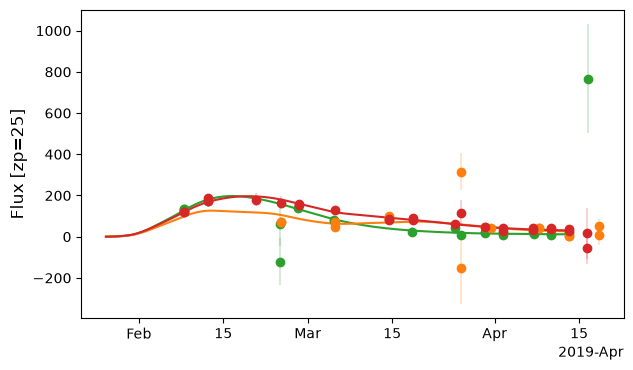

In [6]:
ndetection_good = ndetection.loc[good]
typical = (ndetection_good - ndetection_good.median()).abs().idxmin()
fig = dset.show_target_lightcurve(index=typical, phase_window=[-20, 60])

### Option 1: sncosmo, one target at a time

{func}`skysurvey.lcfit.fit_salt` loops over the targets and fits each lightcurve with {func}`sncosmo.fit_lc`
(redshift fixed, `t0`, `x0`, `x1` and `c` free, SALT2 model covariance included).

:::{important}
`fit_salt` starts each fit from the **true** parameters (with a small random scatter, `in_scatter`) and bounds the
fitted values to `bounds` around this starting point. This is a convenient shortcut for simulations, but the
default bounds ($\pm0.4$ in `x1`, $\pm0.2$ in `c`) can truncate the fit: we widen them here.
:::

:::{tip}
`fit_salt` accepts a `dask.distributed.Client` (`client=`) to run the fits in parallel.
:::

In [7]:
# the simulated fluxes are in the AB system; sncosmo needs it as an explicit column.
dset.data["zpsys"] = "ab"

start = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore") # sncosmo/iminuit convergence chatter
    fits_sncosmo = fit_salt(dset, indexes=good, phase_range=phase_range,
                            bounds={"t0": 10, "x1": 4, "c": 0.6})
timings["4b. fit (sncosmo)"] = time.perf_counter() - start

fits_sncosmo = fits_sncosmo.astype(float)
print(f"{len(fits_sncosmo):,} fits in {timings['4b. fit (sncosmo)']:.0f} s "
      f"({timings['4b. fit (sncosmo)'] / len(good) * 1e3:.0f} ms per SN)")
fits_sncosmo[["z", "t0", "x0", "x1", "x1_err", "c", "c_err"]].head()

3,285 fits in 302 s (92 ms per SN)


,z,t0,x0,x1,x1_err,c,c_err
1,0.09965,58531.398784,0.000293,0.683261,0.318010,0.054535,0.034324
2,0.07525,58823.483915,0.000602,-0.241567,0.130960,-0.000297,0.028052
3,0.04175,58584.598532,0.002844,0.999509,0.120086,-0.003189,0.026464
6,0.07065,58847.483726,0.000336,0.625565,0.757902,0.246831,0.097041
7,0.09855,58749.082074,0.000323,-1.156107,0.180048,0.034495,0.029553


### Option 2: saltjax, all targets at once

{func}`skysurvey.lcfit.fit_salt_jax` fits all the lightcurves together with
[saltjax](https://github.com/MickaelRigault/saltjax), a JAX implementation of the same SALT2 model, chi2 and
model-covariance procedure. Unlike `fit_salt`, it starts from a guess computed **from the data** (not from the
truth) and the parameters are not bounded. It also returns the fit `chi2`, `ndof` and a `converged` flag.

saltjax only fits the targets with more than 4 data points (any S/N) within `phase_range`, and warns about the fits
that need attention (no convergence, invalid covariance, extreme color).

In [8]:
start = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore") # saltjax summary warnings, see the converged and valid columns
    fits_jax = fit_salt_jax(dset, indexes=good, phase_range=phase_range)
timings["4c. fit (saltjax)"] = time.perf_counter() - start

print(f"{len(fits_jax):,} fits in {timings['4c. fit (saltjax)']:.0f} s "
      f"({timings['4c. fit (saltjax)'] / len(good) * 1e3:.0f} ms per SN), "
      f"{fits_jax['converged'].mean():.1%} converged")
fits_jax[["z", "t0", "x0", "x1", "x1_err", "c", "c_err", "chi2", "ndof", "converged"]].head()

3,285 fits in 36 s (11 ms per SN), 99.7% converged


,z,t0,x0,x1,x1_err,c,c_err,chi2,ndof,converged
1,0.09965,58531.399161,0.000293,0.682788,0.318224,0.054580,0.034327,48.339705,42.0,True
2,0.07525,58823.483916,0.000602,-0.241567,0.130997,-0.000299,0.028068,308.448003,322.0,True
3,0.04175,58584.598804,0.002844,0.999491,0.120113,-0.003323,0.026469,2.968719,9.0,True
6,0.07065,58847.486244,0.000335,0.633265,0.763220,0.247801,0.097348,18.148468,17.0,True
7,0.09855,58749.082071,0.000323,-1.156107,0.180138,0.034494,0.029569,73.855023,87.0,True


The first call to `fit_salt_jax` includes the JAX compilation of the model. Calling it again (e.g. on
another dataset) is faster:

In [9]:
start = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    _ = fit_salt_jax(dset, indexes=good, phase_range=phase_range)
timings["4d. fit (saltjax, 2nd call)"] = time.perf_counter() - start
print(f"second call: {timings['4d. fit (saltjax, 2nd call)']:.0f} s")

second call: 23 s


### Do the fits recover the truth?

Since this is a simulation, we know the true parameters. For both fitters, the fitted `x1` and `c` follow the
true values, with a scatter given by the fit errors (larger at high redshift, where SNe are fainter).

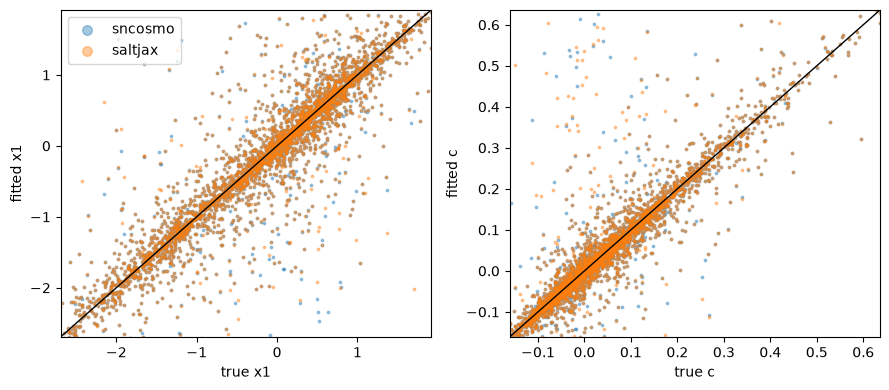

In [10]:
truth = snia.data
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, key in zip(axes, ["x1", "c"]):
    for fits_, label in [(fits_sncosmo, "sncosmo"), (fits_jax.query("converged"), "saltjax")]:
        ax.scatter(truth.loc[fits_.index, key], fits_[key], s=3, alpha=0.4, label=label)

    lims = np.percentile(truth.loc[good, key], [0.5, 99.5])
    ax.plot(lims, lims, color="k", lw=1)
    ax.set(xlim=lims, ylim=lims, xlabel=f"true {key}", ylabel=f"fitted {key}")

axes[0].legend(markerscale=4)
fig.tight_layout()

Both fitters agree with each other: the difference between their `x1` and `c` estimates is much smaller
than the fit errors.

In [11]:
both = fits_sncosmo.index.intersection(fits_jax.query("converged").index)
for key in ["x1", "c"]:
    diff = fits_jax.loc[both, key] - fits_sncosmo.loc[both, key]
    print(f"{key}: median |saltjax - sncosmo| = {diff.abs().median():.4f}, "
          f"median error = {fits_sncosmo.loc[both, f'{key}_err'].median():.3f}")

x1: median |saltjax - sncosmo| = 0.0002, median error = 0.220
c: median |saltjax - sncosmo| = 0.0001, median error = 0.033


## Timing summary

The full chain, from the real ZTF logs to SALT2 parameters, for one year of SNe Ia up to $z=0.1$:

In [12]:
pandas.Series(timings, name="time [s]").round(2).to_frame()

,time [s]
1. load survey,1.61
2. draw targets,0.38
3. build dataset,7.65
4a. quality cut,0.04
4b. fit (sncosmo),301.61
4c. fit (saltjax),35.96
"4d. fit (saltjax, 2nd call)",22.79


## Going further

- {doc}`../examples/snia_hubble_diagram`: standardize the fitted SNe Ia and build a Hubble diagram.
- {doc}`../examples/detection_efficiency`: measure what fraction of the SNe your survey detects.
- {doc}`quickstart_survey`: build your own survey from a list of pointings.